# 📊 Customer360: Customer Churn Prediction & Retention Intelligence Platform
## Phase 1: Data Understanding & Exploratory Data Analysis (EDA)

---

### 🎯 Business Objective
Customer retention is crucial for telecommunications and subscription-based enterprises. Acquiring new customers typically costs 5 to 7 times more than retaining existing ones. The goal of the **Customer360** initiative is to identify customer churn patterns, isolate root-cause churn drivers, and build an actionable intelligence platform to power targeted retention campaigns.

### 📌 Notebook Scope & Guidelines
1. **Data Ingestion**: Load the raw customer dataset using robust relative paths.
2. **Schema & Structural Inspection**: Verify dataset dimensions, column names, and data types.
3. **Statistical Profiling**: Generate parametric and non-parametric statistical summaries.
4. **Data Integrity & Quality Audit**: Assess missing values, duplicate records, customer ID uniqueness, and anomaly detection (e.g., blank strings in `TotalCharges`).
5. **Target Variable Diagnostics**: Analyze the distribution of `Churn` and quantify class imbalance.
6. **Bivariate & Multivariate Explorations**:
   - Churn vs. Contract Type
   - Churn vs. Payment Method
   - Churn vs. Internet Service
   - Churn vs. Tenure Distribution
   - Churn vs. Monthly Charges Distribution
   - Churn vs. Senior Citizen Status
7. **Numerical Correlations & Feature Interactions**: Evaluate inter-feature relationships and potential multicollinearity.
8. **Actionable Business Insights**: Synthesize key analytical findings into concrete retention strategies.

> **Note**: In compliance with the project governance rules, the raw dataset (`data/raw/customer_churn.csv`) remains untouched and pristine. No feature engineering or model training is conducted within this initial phase.

### 1. Environment Setup & Visualization Aesthetics
We import standard data science and visualization libraries, configuring consistent, publication-ready plot aesthetics.

In [1]:
import sys
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor future warnings
warnings.filterwarnings('ignore')

# Visual styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 100

# Consistent color palette for Churn analysis
# Blue (#2563EB) for Retained ('No') and Red/Coral (#EF4444) for Churned ('Yes')
CHURN_PALETTE = {'No': '#2563EB', 'Yes': '#EF4444'}
CATEGORICAL_PALETTE = ['#3B82F6', '#10B981', '#F59E0B', '#8B5CF6', '#EC4899', '#6B7280']

print("Libraries imported and plotting theme successfully initialized.")

Libraries imported and plotting theme successfully initialized.


### 2. Data Ingestion via Relative Path
We dynamically resolve the path to `data/raw/customer_churn.csv` so that the notebook can be executed seamlessly from either the project root or the `notebooks/` directory.

We also instantiate a working DataFrame `df` so that the original dataset remains untouched.

In [2]:
# Robust relative path resolution
candidate_paths = [
    Path("../data/raw/customer_churn.csv"),
    Path("data/raw/customer_churn.csv"),
    Path.cwd() / "data" / "raw" / "customer_churn.csv",
    Path.cwd().parent / "data" / "raw" / "customer_churn.csv"
]

data_path = None
for p in candidate_paths:
    if p.resolve().exists():
        data_path = p.resolve()
        break

if data_path is None:
    raise FileNotFoundError("Could not locate 'customer_churn.csv' in expected data directories.")

print(f"Loading dataset from: {data_path.name}")
print(f"Absolute path: {data_path}")

# Load raw dataset
df_raw = pd.read_csv(data_path)

# Create an explicit working copy for EDA
df = df_raw.copy()
print(f"Successfully loaded {len(df):,} records and {df.shape[1]} attributes.")

Loading dataset from: customer_churn.csv
Absolute path: C:\Users\USER\OneDrive\Desktop\Customer 360\data\raw\customer_churn.csv
Successfully loaded 7,043 records and 21 attributes.


### 3. Dataset Dimensions, Schema & Data Types
Let's inspect the dimensions, column inventory, and data type mappings.

In [3]:
print(f"Total Observations (Rows)   : {df.shape[0]:,}")
print(f"Total Features     (Columns): {df.shape[1]:,}")

# Tabular overview of column data types and non-null counts
schema_summary = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.values,
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Unique Values': [df[col].nunique() for col in df.columns],
    'Sample Value': [df[col].iloc[0] for col in df.columns]
})

schema_summary

Total Observations (Rows)   : 7,043
Total Features     (Columns): 21


,Column Name,Data Type,Non-Null Count,Null Count,Unique Values,Sample Value
0,customerID,str,7043,0,7043,7590-VHVEG
1,gender,str,7043,0,2,Female
2,SeniorCitizen,int64,7043,0,2,0
3,Partner,str,7043,0,2,Yes
4,Dependents,str,7043,0,2,No
5,tenure,int64,7043,0,73,1
6,PhoneService,str,7043,0,2,No
7,MultipleLines,str,7043,0,3,No phone service
8,InternetService,str,7043,0,3,DSL
9,OnlineSecurity,str,7043,0,3,No


Let's preview the top 5 records of the dataset.

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 4. Statistical Profiling
We examine descriptive statistics for both numeric and categorical variables.

In [5]:
print("--- Numerical Attributes Summary ---")
df.describe().T

--- Numerical Attributes Summary ---


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


**Observation on Numerical Summary**:
- `SeniorCitizen` is encoded as binary `0` and `1`, with a mean of `0.162` indicating that approximately 16.2% of the customer base are senior citizens.
- `tenure` ranges from `0` to `72` months (6 years), with an average tenure of ~32.4 months and median of 29 months.
- `MonthlyCharges` ranges from `$18.25` to `$118.75`, with a mean of `$64.76` and median of `$70.35`.
- Note: `TotalCharges` is currently stored as an `object` (string) data type rather than float. We will audit this anomaly next.

Now let's examine the categorical features:

In [6]:
print("--- Categorical Attributes Summary ---")
df.describe(include=['O']).T

--- Categorical Attributes Summary ---


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


### 5. Data Quality, Integrity & Anomaly Detection
We verify:
1. Missing / null values across all attributes.
2. Duplicate customer records.
3. Uniqueness of customer IDs.
4. Detailed inspection of `TotalCharges`.

In [7]:
# 1. Missing values check
null_counts = df.isnull().sum()
total_nulls = null_counts.sum()
print(f"Total Standard Null (NaN) Values in Dataset: {total_nulls}")

# 2. Duplicate records check
duplicate_rows = df.duplicated().sum()
print(f"Total Duplicate Rows: {duplicate_rows}")

# 3. Customer ID uniqueness check
unique_ids = df['customerID'].nunique()
total_records = len(df)
print(f"Total Records: {total_records} | Unique Customer IDs: {unique_ids}")
print(f"Is each row a distinct unique customer? {'Yes (100% Unique)' if unique_ids == total_records else 'No'}")

Total Standard Null (NaN) Values in Dataset: 0
Total Duplicate Rows: 0
Total Records: 7043 | Unique Customer IDs: 7043
Is each row a distinct unique customer? Yes (100% Unique)


#### ⚠️ TotalCharges Anomaly Audit
In the schema summary, `TotalCharges` was loaded as an `object` (string) rather than a floating-point numeric value. Let's inspect why.

In [8]:
# Check for blank / whitespace strings in TotalCharges
blank_strings = (df['TotalCharges'].str.strip() == '').sum()
print(f"Number of rows with blank strings (' ') in TotalCharges: {blank_strings}")

# Inspect the records where TotalCharges is blank
blank_tc_rows = df[df['TotalCharges'].str.strip() == '']
blank_tc_rows[['customerID', 'tenure', 'Contract', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Number of rows with blank strings (' ') in TotalCharges: 11


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


**Critical Finding on `TotalCharges`**:
- There are exactly **11 rows** where `TotalCharges` contains a whitespace string (`" "`).
- For all 11 of these customers, `tenure == 0`.
- This reveals that these are brand-new customers who have just subscribed and have not yet completed their first billing cycle.
- Notice also that all 11 have `Churn == 'No'`.
- **Handling Strategy for EDA**:
  We convert `TotalCharges` to numeric using `pd.to_numeric(df['TotalCharges'], errors='coerce')` in a dedicated EDA column `TotalCharges_Numeric` without modifying the original dataset file. For the 11 zero-tenure records, their total cumulative charge is conceptually $0.00.

In [9]:
# Create numeric representation for EDA without modifying raw data
df['TotalCharges_Numeric'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# For the 11 brand new customers (tenure == 0), TotalCharges can be imputed as 0 for EDA plotting
df['TotalCharges_Cleaned'] = df['TotalCharges_Numeric'].fillna(0.0)

print(f"Missing values before coercion: {df['TotalCharges'].isnull().sum()}")
print(f"Missing values after coercion: {df['TotalCharges_Numeric'].isnull().sum()} (corresponding to tenure=0)")
print(f"TotalCharges_Cleaned nulls: {df['TotalCharges_Cleaned'].isnull().sum()}")
print(f"TotalCharges_Cleaned summary stats:\n{df['TotalCharges_Cleaned'].describe()}")

Missing values before coercion: 0
Missing values after coercion: 11 (corresponding to tenure=0)
TotalCharges_Cleaned nulls: 0
TotalCharges_Cleaned summary stats:
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges_Cleaned, dtype: float64


### 6. Target Variable Analysis (`Churn`) & Class Imbalance
Here we evaluate the target variable distribution and quantify the degree of class imbalance.

In [10]:
# Value counts and percentages
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    'Count': churn_counts,
    'Percentage (%)': churn_pct.round(2)
})

imbalance_ratio = churn_counts['No'] / churn_counts['Yes']
print(f"Class Imbalance Ratio (No : Yes) = {imbalance_ratio:.2f} : 1")
churn_summary

Class Imbalance Ratio (No : Yes) = 2.77 : 1


,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


findfont: Failed to find font weight semibold for Arial, now using 700.


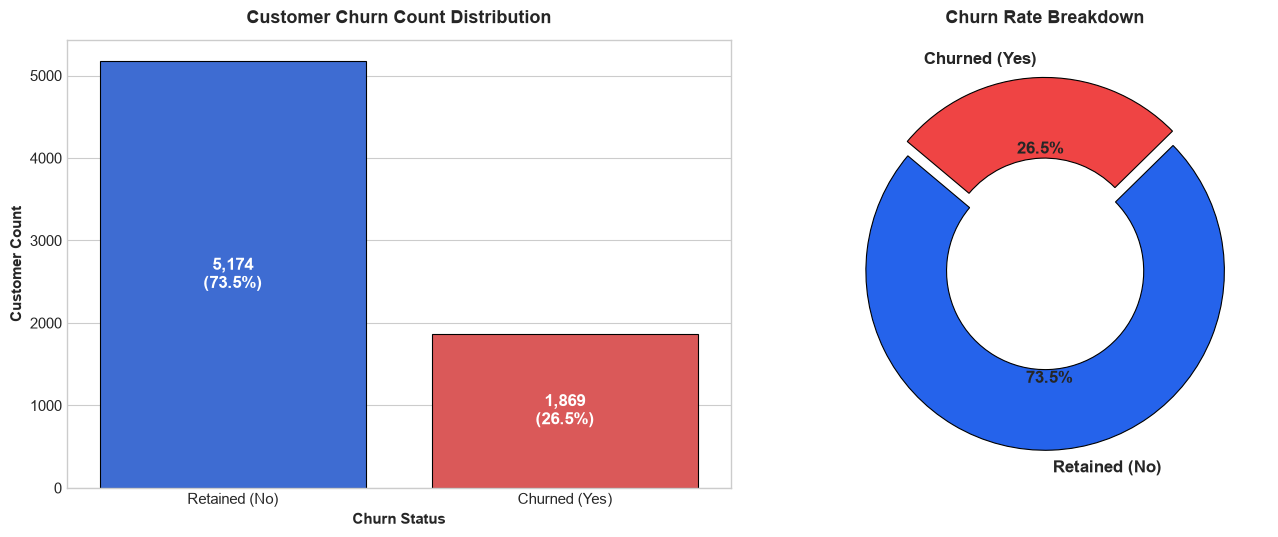

In [11]:
# Visualizing Target Variable Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Countplot with bar percentage labels
sns.countplot(
    data=df,
    x='Churn',
    palette=CHURN_PALETTE,
    order=['No', 'Yes'],
    ax=axes[0],
    edgecolor='black',
    linewidth=0.8
)
axes[0].set_title("Customer Churn Count Distribution", weight='bold', pad=12)
axes[0].set_xlabel("Churn Status", weight='semibold')
axes[0].set_ylabel("Customer Count", weight='semibold')
axes[0].set_xticklabels(['Retained (No)', 'Churned (Yes)'])

# Annotate bars with counts and percentages
total = len(df)
for p in axes[0].patches:
    height = p.get_height()
    pct = (height / total) * 100
    axes[0].annotate(f"{int(height):,}\n({pct:.1f}%)",
                     (p.get_x() + p.get_width() / 2., height / 2),
                     ha='center', va='center', color='white', weight='bold', fontsize=12)

# Subplot 2: Donut Chart
axes[1].pie(
    churn_counts,
    labels=['Retained (No)', 'Churned (Yes)'],
    autopct='%1.1f%%',
    startangle=140,
    colors=[CHURN_PALETTE['No'], CHURN_PALETTE['Yes']],
    explode=(0.04, 0.04),
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=0.8),
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[1].set_title("Churn Rate Breakdown", weight='bold', pad=12)

plt.tight_layout()
plt.show()

**Takeaway on Target Distribution & Class Imbalance**:
- **73.46% (5,174 customers)** remained with the company.
- **26.54% (1,869 customers)** churned within the observed window.
- The dataset exhibits a **moderate class imbalance ratio of ~2.77 : 1**.
- **Modeling Implications**:
  1. A naive baseline model predicting "No" would achieve ~73.5% accuracy while failing completely at identifying churners.
  2. Standard Accuracy will be a misleading metric. Evaluation during subsequent modeling must focus on **PR-AUC, ROC-AUC, Precision, Recall, and F1-Score (macro / class 1)**.
  3. Resampling techniques (SMOTE / Random Under-Sampling) or algorithmic cost-weighting (`scale_pos_weight` in XGBoost, `class_weight='balanced'` in logistic regression/random forest) should be evaluated during modeling.

### 7. Categorical Drivers of Churn
We explore key contract, billing, service, and demographic factors to uncover behavioral drivers of churn.

In [12]:
# Helper function to generate clean stacked percentage and volume plots
def plot_categorical_churn(df, col, title, ax1, ax2, order=None):
    # Cross tabulation
    ct = pd.crosstab(df[col], df['Churn'], normalize='index') * 100
    counts = pd.crosstab(df[col], df['Churn'])
    
    if order:
        ct = ct.reindex(order)
        counts = counts.reindex(order)
        
    # Plot 1: Absolute volume by segment
    counts[['No', 'Yes']].plot(
        kind='bar',
        ax=ax1,
        color=[CHURN_PALETTE['No'], CHURN_PALETTE['Yes']],
        edgecolor='black',
        linewidth=0.8,
        rot=0
    )
    ax1.set_title(f"{title}: Customer Volume", weight='bold')
    ax1.set_ylabel("Customer Count", weight='semibold')
    ax1.set_xlabel("")
    ax1.legend(['Retained (No)', 'Churned (Yes)'], title="Churn")
    
    # Plot 2: Churn Rate (%)
    churn_rate = ct['Yes']
    bars = ax2.bar(churn_rate.index, churn_rate.values, color='#EF4444', edgecolor='black', linewidth=0.8)
    ax2.set_title(f"{title}: Churn Rate (%)", weight='bold')
    ax2.set_ylabel("Churn Rate (%)", weight='semibold')
    ax2.set_xlabel("")
    ax2.axhline(df['Churn'].value_counts(normalize=True)['Yes'] * 100, color='black', linestyle='--', linewidth=1.2, label=f"Average Churn ({df['Churn'].value_counts(normalize=True)['Yes']*100:.1f}%)")
    ax2.legend()
    
    # Annotate percentages on bars
    for bar in bars:
        height = bar.get_height()
        ax2.annotate(f"{height:.1f}%",
                     (bar.get_x() + bar.get_width() / 2., height + 1),
                     ha='center', va='bottom', weight='bold', fontsize=10)
    ax2.set_ylim(0, max(churn_rate.values) + 12)

#### A. Churn by Contract Type
Contract commitment is typically one of the strongest determinants of retention.

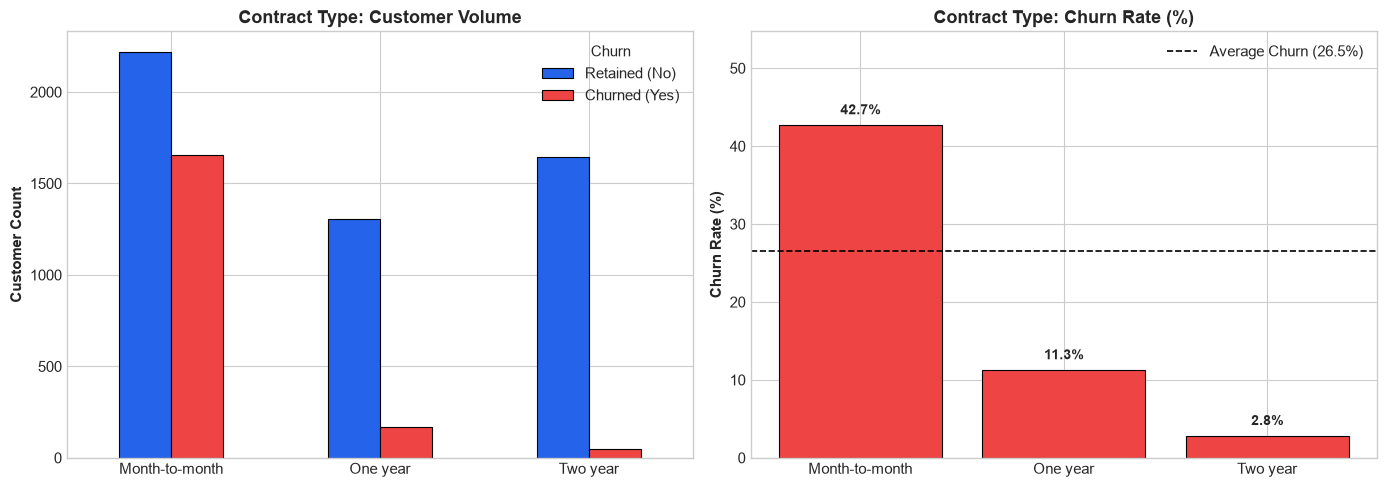

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_categorical_churn(
    df, 
    col='Contract', 
    title='Contract Type', 
    ax1=axes[0], 
    ax2=axes[1],
    order=['Month-to-month', 'One year', 'Two year']
)
plt.tight_layout()
plt.show()

contract_analysis = df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(2)
print("Churn Rate by Contract Type:")
print(contract_analysis)

**Contract Type Insights**:
- **Month-to-month contracts** suffer from an alarming **42.71% churn rate**.
- In stark contrast, **One-year contracts** experience only **11.27% churn**, and **Two-year contracts** experience a minuscule **2.83% churn**.
- Customers on month-to-month terms have zero friction to switch providers, making contract migration (e.g., promotional discounts for annual commitment) a prime retention strategy.

#### B. Churn by Payment Method
Payment channel friction and billing automation play a substantial role in subscription continuity.

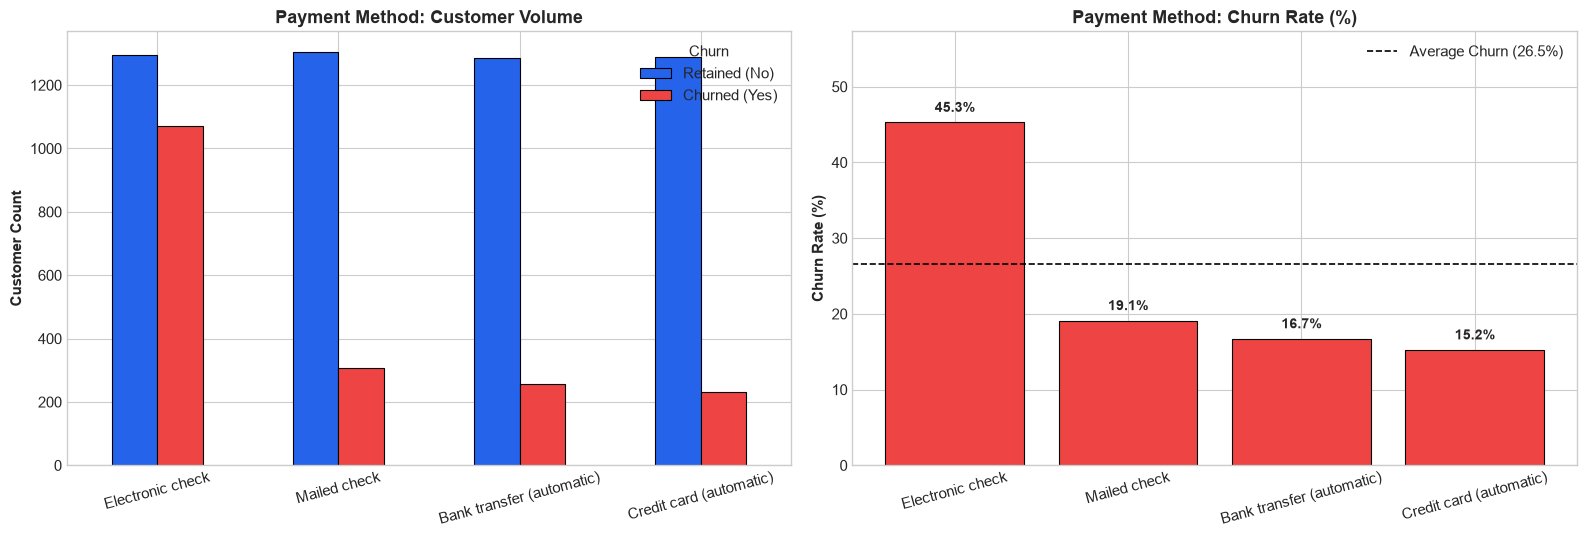

Churn Rate by Payment Method:
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
plot_categorical_churn(
    df, 
    col='PaymentMethod', 
    title='Payment Method', 
    ax1=axes[0], 
    ax2=axes[1],
    order=['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
)
axes[0].tick_params(axis='x', rotation=15)
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

payment_analysis = df.groupby('PaymentMethod')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(2)
print("Churn Rate by Payment Method:")
print(payment_analysis)

**Payment Method Insights**:
- Customers utilizing **Electronic check** exhibit an exceptionally high churn rate of **45.29%**, making it the riskiest payment channel.
- In contrast, automated billing options—**Credit card (automatic)** at **15.24%** and **Bank transfer (automatic)** at **16.71%**—have churn rates almost three times lower.
- This points to friction in manual monthly payments, transaction failures, or lack of customer commitment among electronic check users.

#### C. Churn by Internet Service
Evaluating product line churn across DSL, Fiber optic, and customers with no internet service.

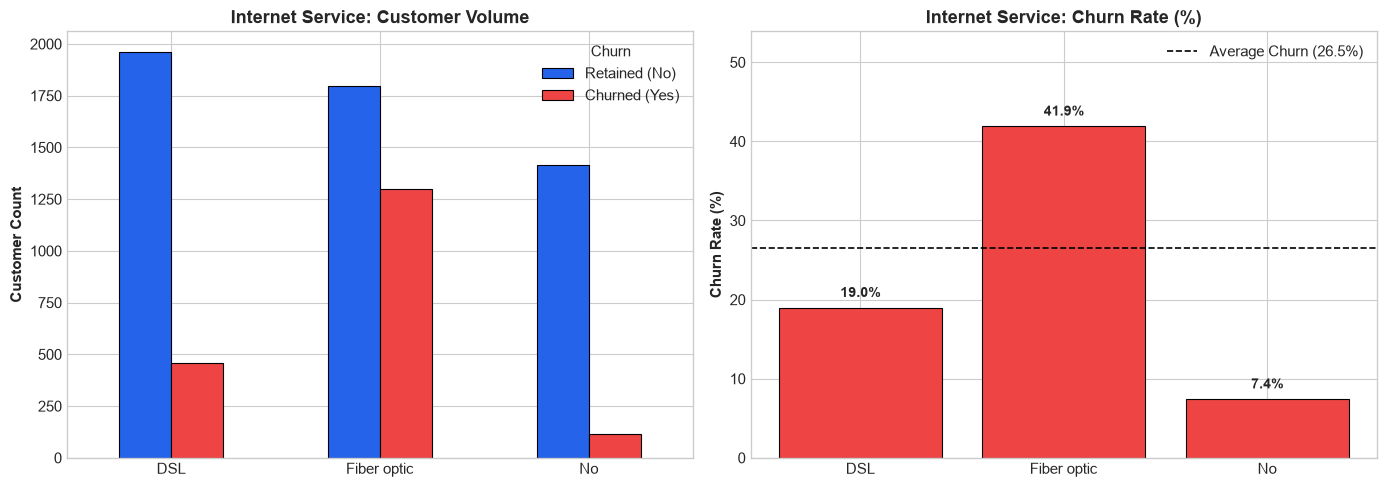

Churn Rate by Internet Service:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_categorical_churn(
    df, 
    col='InternetService', 
    title='Internet Service', 
    ax1=axes[0], 
    ax2=axes[1],
    order=['DSL', 'Fiber optic', 'No']
)
plt.tight_layout()
plt.show()

internet_analysis = df.groupby('InternetService')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(2)
print("Churn Rate by Internet Service:")
print(internet_analysis)

**Internet Service Insights**:
- **Fiber optic customers** experience a disproportionately high churn rate of **41.89%**, despite fiber typically being a flagship, premium offering.
- **DSL customers** churn at **18.96%**, while customers with **No internet service** churn at just **7.40%**.
- High fiber churn suggests potential issues with service reliability, expectation mismatch, or aggressive competitor pricing in high-speed markets.

#### D. Churn by Senior Citizen Status
We examine demographic vulnerability across age brackets.

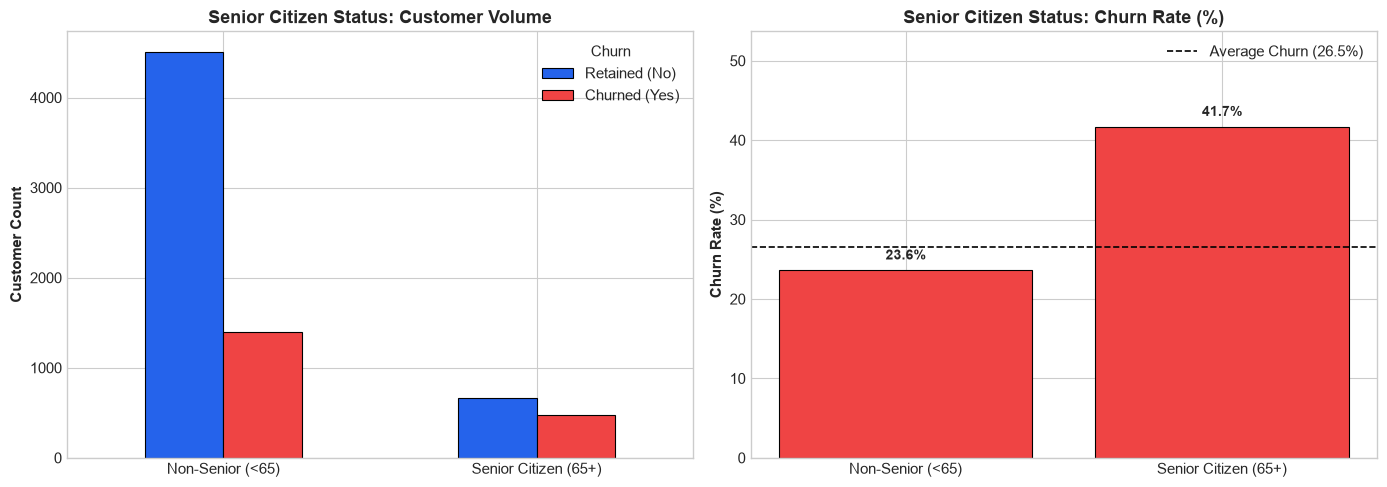

Churn Rate by Senior Citizen Status:
SeniorCitizen_Label
Non-Senior (<65)        23.61
Senior Citizen (65+)    41.68
Name: Churn, dtype: float64


In [16]:
# Add readable label for plotting
df['SeniorCitizen_Label'] = df['SeniorCitizen'].map({0: 'Non-Senior (<65)', 1: 'Senior Citizen (65+)'})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_categorical_churn(
    df, 
    col='SeniorCitizen_Label', 
    title='Senior Citizen Status', 
    ax1=axes[0], 
    ax2=axes[1],
    order=['Non-Senior (<65)', 'Senior Citizen (65+)']
)
plt.tight_layout()
plt.show()

senior_analysis = df.groupby('SeniorCitizen_Label')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(2)
print("Churn Rate by Senior Citizen Status:")
print(senior_analysis)

**Senior Citizen Insights**:
- **Senior Citizens** experience a **41.68% churn rate**, compared to **23.61%** for non-seniors.
- Seniors represent a more vulnerable cohort, potentially needing simplified billing, dedicated technical support, or senior-targeted plans.

### 8. Numerical Drivers of Churn: Tenure & Charges Analysis
We examine the continuous numerical features: `tenure`, `MonthlyCharges`, and `TotalCharges`.

#### A. Tenure Distribution & The "Early Tenure Cliff"
How does tenure length relate to customer attrition?

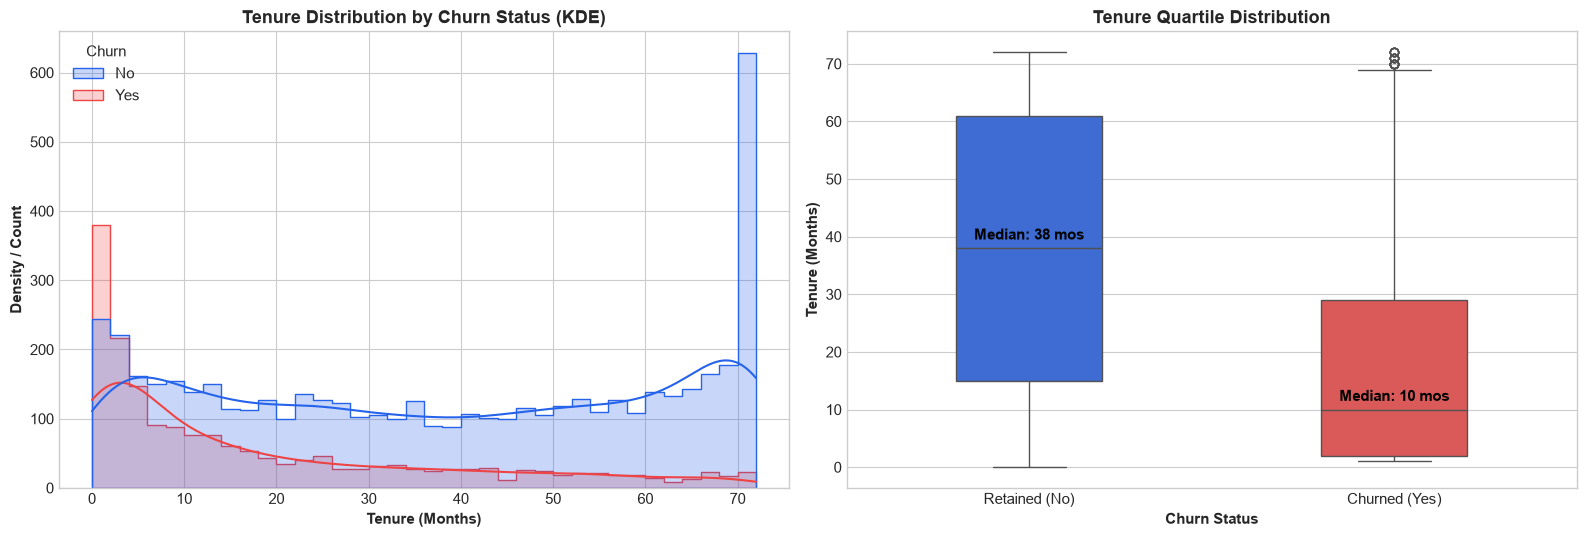

Tenure Statistics by Churn:
        count       mean        std  min   25%   50%   75%   max
Churn                                                           
No     5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Plot 1: Histogram & KDE of Tenure by Churn
sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    palette=CHURN_PALETTE,
    kde=True,
    bins=36,
    element='step',
    common_norm=False,
    ax=axes[0]
)
axes[0].set_title("Tenure Distribution by Churn Status (KDE)", weight='bold')
axes[0].set_xlabel("Tenure (Months)", weight='semibold')
axes[0].set_ylabel("Density / Count", weight='semibold')

# Plot 2: Boxplot & Quartiles
sns.boxplot(
    data=df,
    x='Churn',
    y='tenure',
    palette=CHURN_PALETTE,
    order=['No', 'Yes'],
    ax=axes[1],
    width=0.4
)
axes[1].set_title("Tenure Quartile Distribution", weight='bold')
axes[1].set_xlabel("Churn Status", weight='semibold')
axes[1].set_ylabel("Tenure (Months)", weight='semibold')
axes[1].set_xticklabels(['Retained (No)', 'Churned (Yes)'])

# Annotate median values
medians = df.groupby('Churn')['tenure'].median()
for i, (churn_val, median_val) in enumerate(medians.items()):
    axes[1].text(i, median_val + 1.5, f"Median: {median_val:.0f} mos", 
                 horizontalalignment='center', weight='bold', color='black')

plt.tight_layout()
plt.show()

print("Tenure Statistics by Churn:")
print(df.groupby('Churn')['tenure'].describe())

**Tenure Insights**:
- Churned customers have a **median tenure of only 10.0 months**, compared to **38.0 months** for retained customers.
- 25% of churned customers leave within the **first 2 months**, and 75% churn before reaching 29 months.
- The tenure distribution reveals a sharp **"Early Tenure Cliff"**: the risk of attrition is exceptionally concentrated in months 1 to 6. Once a customer surpasses ~24 months, retention likelihood increases dramatically.

#### B. Monthly Charges Distribution & Price Sensitivity
Does higher monthly pricing directly drive customer departure?

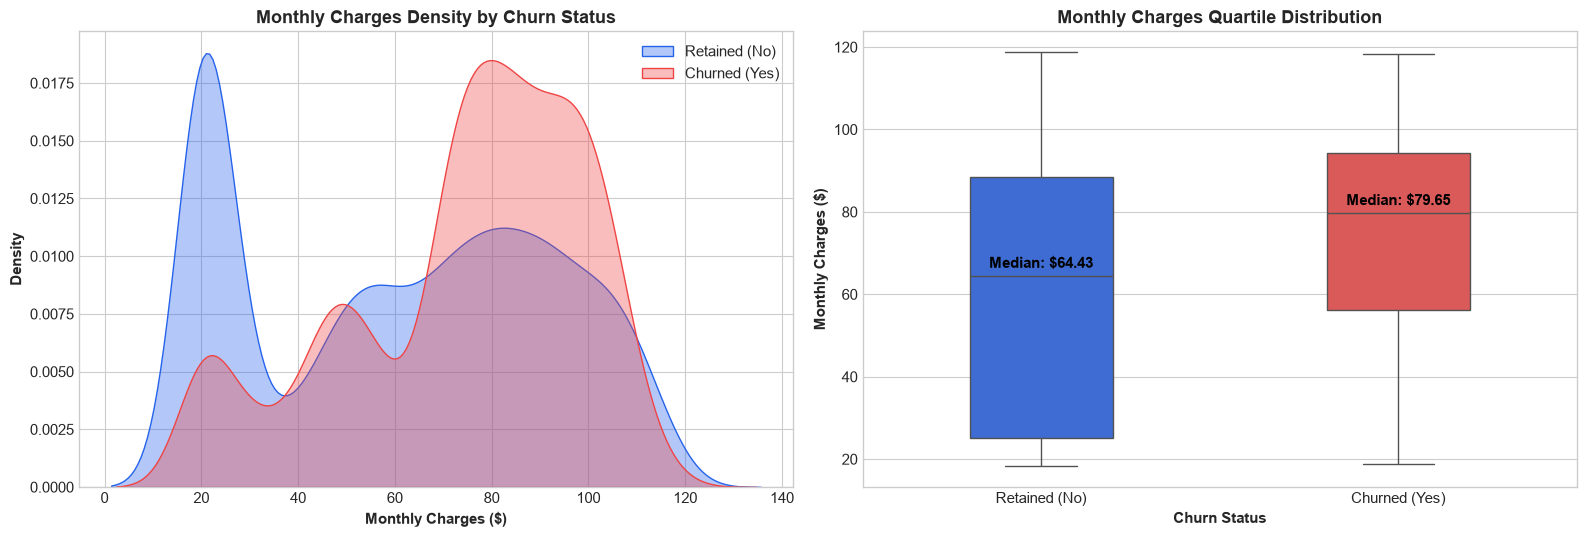

Monthly Charges Statistics by Churn:
        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
No     5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
Yes    1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Plot 1: KDE of Monthly Charges
sns.kdeplot(
    data=df[df['Churn'] == 'No']['MonthlyCharges'],
    label='Retained (No)',
    color=CHURN_PALETTE['No'],
    fill=True,
    alpha=0.35,
    ax=axes[0]
)
sns.kdeplot(
    data=df[df['Churn'] == 'Yes']['MonthlyCharges'],
    label='Churned (Yes)',
    color=CHURN_PALETTE['Yes'],
    fill=True,
    alpha=0.35,
    ax=axes[0]
)
axes[0].set_title("Monthly Charges Density by Churn Status", weight='bold')
axes[0].set_xlabel("Monthly Charges ($)", weight='semibold')
axes[0].set_ylabel("Density", weight='semibold')
axes[0].legend()

# Plot 2: Boxplot
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    palette=CHURN_PALETTE,
    order=['No', 'Yes'],
    ax=axes[1],
    width=0.4
)
axes[1].set_title("Monthly Charges Quartile Distribution", weight='bold')
axes[1].set_xlabel("Churn Status", weight='semibold')
axes[1].set_ylabel("Monthly Charges ($)", weight='semibold')
axes[1].set_xticklabels(['Retained (No)', 'Churned (Yes)'])

# Annotate median values
mc_medians = df.groupby('Churn')['MonthlyCharges'].median()
for i, (churn_val, median_val) in enumerate(mc_medians.items()):
    axes[1].text(i, median_val + 2, f"Median: ${median_val:.2f}", 
                 horizontalalignment='center', weight='bold', color='black')

plt.tight_layout()
plt.show()

print("Monthly Charges Statistics by Churn:")
print(df.groupby('Churn')['MonthlyCharges'].describe())

**Monthly Charges Insights**:
- The median monthly charge for **churned customers is $79.65**, significantly higher than the **$64.43 median for retained customers** (a ~$15/month premium).
- Customers in the $70–$100 range exhibit elevated churn density.
- Conversely, customers in the low-cost tier ($18–$30/month, mostly basic phone or no-internet users) show very high loyalty and low churn rates.

#### C. Total Charges Distribution
Examining lifetime cumulative charges across customer segments.

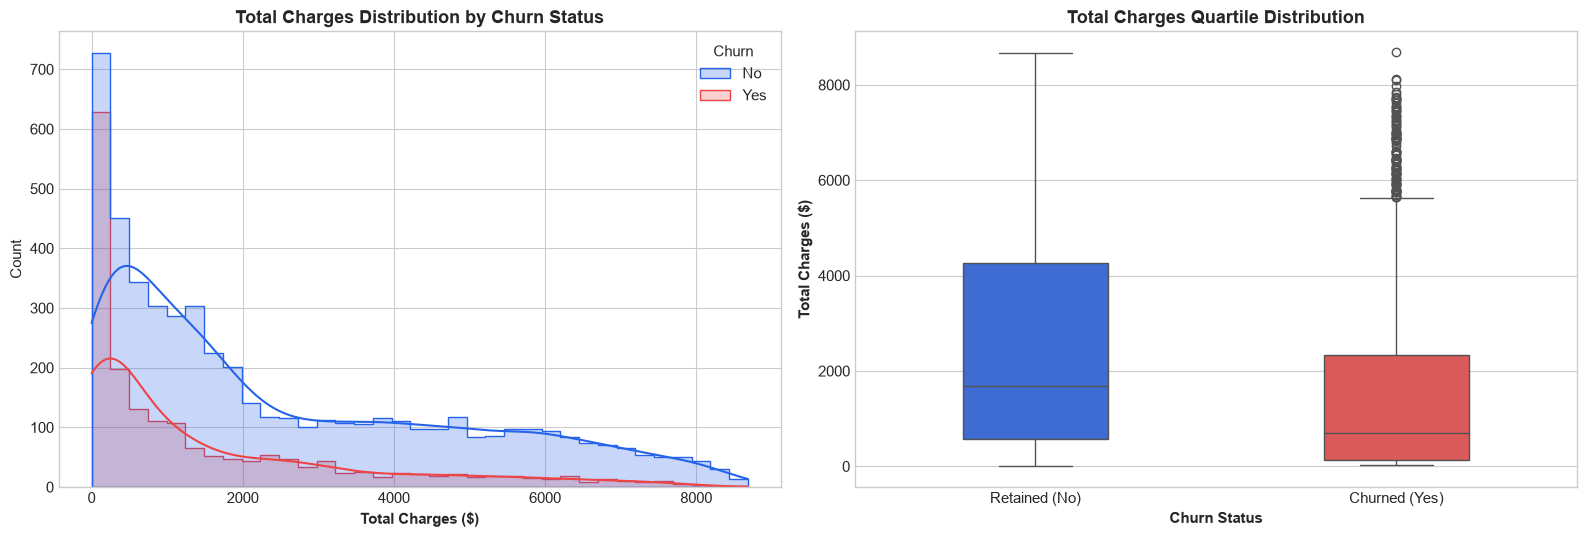

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.histplot(
    data=df,
    x='TotalCharges_Cleaned',
    hue='Churn',
    palette=CHURN_PALETTE,
    kde=True,
    bins=35,
    element='step',
    common_norm=False,
    ax=axes[0]
)
axes[0].set_title("Total Charges Distribution by Churn Status", weight='bold')
axes[0].set_xlabel("Total Charges ($)", weight='semibold')

sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges_Cleaned',
    palette=CHURN_PALETTE,
    order=['No', 'Yes'],
    ax=axes[1],
    width=0.4
)
axes[1].set_title("Total Charges Quartile Distribution", weight='bold')
axes[1].set_xlabel("Churn Status", weight='semibold')
axes[1].set_ylabel("Total Charges ($)", weight='semibold')
axes[1].set_xticklabels(['Retained (No)', 'Churned (Yes)'])

plt.tight_layout()
plt.show()

### 9. Relationships Between Numerical Variables & Multicollinearity
We examine the pairwise correlations between numerical variables (`tenure`, `MonthlyCharges`, `TotalCharges_Cleaned`) and explore whether multicollinearity is present.

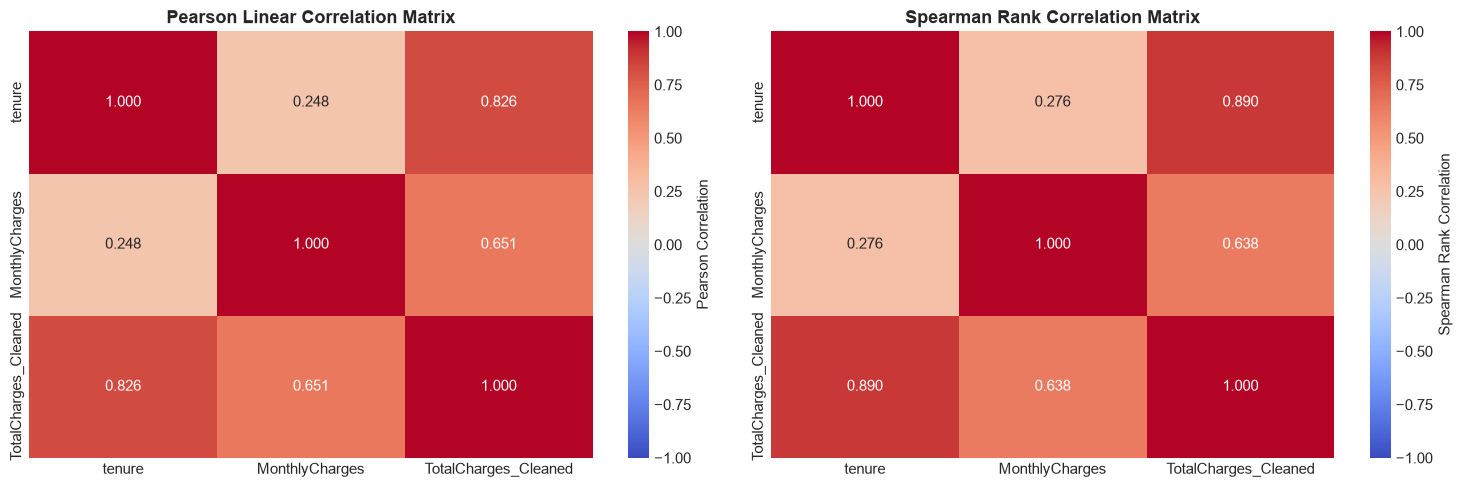

In [20]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges_Cleaned']
corr_pearson = df[numeric_cols].corr(method='pearson')
corr_spearman = df[numeric_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Pearson Correlation Heatmap
sns.heatmap(
    corr_pearson, 
    annot=True, 
    fmt='.3f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    ax=axes[0], 
    cbar_kws={'label': 'Pearson Correlation'}
)
axes[0].set_title("Pearson Linear Correlation Matrix", weight='bold')

# Spearman Rank Correlation Heatmap
sns.heatmap(
    corr_spearman, 
    annot=True, 
    fmt='.3f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    ax=axes[1], 
    cbar_kws={'label': 'Spearman Rank Correlation'}
)
axes[1].set_title("Spearman Rank Correlation Matrix", weight='bold')

plt.tight_layout()
plt.show()

Now let's examine the interaction between `tenure` and `TotalCharges`, colored by `Churn`.

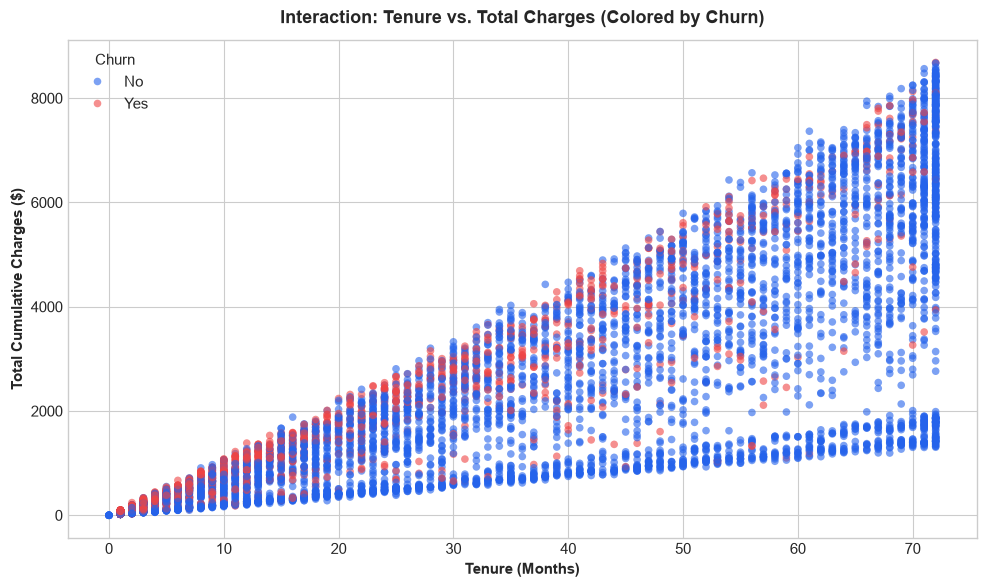

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='tenure',
    y='TotalCharges_Cleaned',
    hue='Churn',
    palette=CHURN_PALETTE,
    alpha=0.6,
    s=30,
    edgecolor='none'
)
plt.title("Interaction: Tenure vs. Total Charges (Colored by Churn)", weight='bold', pad=12)
plt.xlabel("Tenure (Months)", weight='semibold')
plt.ylabel("Total Cumulative Charges ($)", weight='semibold')
plt.legend(title='Churn', loc='upper left')
plt.tight_layout()
plt.show()

**Numerical Relationship & Multicollinearity Findings**:
- **Strong Collinearity**: `tenure` and `TotalCharges` exhibit an extremely high correlation of **0.826 (Pearson)** and **0.889 (Spearman)**. This is mathematically expected since `TotalCharges ≈ tenure * MonthlyCharges`.
- **Feature Engineering / Modeling Note**: In linear models (e.g. Logistic Regression), keeping both raw `tenure` and `TotalCharges` without regularization or feature transformation can introduce severe multicollinearity (high Variance Inflation Factor / VIF). In tree-based ensembles (Random Forest, XGBoost), collinearity is more resilient, but deriving features such as average effective monthly charge (`TotalCharges / tenure`) or interaction terms will be considered in Phase 2.

### 10. Column Inventory & Retention Assessment
In accordance with project guidelines, **no columns are removed from the original data source**. 

Here is our assessment of each feature's role as we transition toward subsequent phases:

| Column Name | Type | Quality Status | Retention Decision & Rationale |
| :--- | :--- | :--- | :--- |
| `customerID` | String | 100% Unique, 0 nulls | **Retain in Raw / Feature Store**: Serves as the primary entity identifier for customer tracking, database storage, and predictions lookup. It will be excluded from the feature matrix $X$ during model training because it has zero predictive generalizability. |
| `gender`, `Partner`, `Dependents` | Categorical | Clean, 0 nulls | **Retain**: Demographic segmentation variables for personalized retention outreach. |
| `SeniorCitizen` | Binary (0/1) | Clean, 0 nulls | **Retain**: Strong demographic risk factor (41.7% churn vs 23.6%). |
| `tenure` | Numeric (int64) | Clean, 0 nulls | **Retain**: Primary predictive signal; captures customer loyalty and lifecycle stage. |
| `PhoneService`, `MultipleLines` | Categorical | Clean, 0 nulls | **Retain**: Telephony service utilization features. |
| `InternetService` | Categorical | Clean, 0 nulls | **Retain**: Critical service tier feature; Fiber Optic segment is high-risk (~41.9% churn). |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Categorical | Clean, 0 nulls | **Retain**: Value-added service adoption features that measure product stickiness. |
| `Contract` | Categorical | Clean, 0 nulls | **Retain**: Top predictor of churn (Month-to-month = 42.7% churn vs Two-year = 2.8%). |
| `PaperlessBilling` | Categorical | Clean, 0 nulls | **Retain**: Digital engagement and billing preference signal. |
| `PaymentMethod` | Categorical | Clean, 0 nulls | **Retain**: Friction indicator (Electronic check = 45.3% churn). |
| `MonthlyCharges` | Float64 | Clean, 0 nulls | **Retain**: Direct measure of customer price point and wallet share. |
| `TotalCharges` | String/Float | 11 blank spaces | **Retain & Preprocess in Pipeline**: Convert to numeric; impute 0 for tenure=0 customers in subsequent data preparation pipeline. |
| `Churn` | Categorical (Yes/No) | Clean, 0 nulls | **Retain**: Target ground truth label for supervised learning. |

### 11. Key Business Insights & Strategic Recommendations

Based on our exploratory data analysis of the 7,043 customer accounts, we have identified **6 core business drivers** and formulated concrete retention strategies:

---

#### 1. Contract Vulnerability (Month-to-Month Risk)
- **Finding**: Customers on Month-to-Month contracts have an alarming **42.71% churn rate**, compared to **11.27%** for One-year and **2.83%** for Two-year contracts. Over 88% of all churners are on month-to-month plans.
- **Actionable Strategy**:
  - Launch targeted contract migration campaigns before month 3, offering small tenure-based discounts or free service upgrades (e.g., speed boost, streaming add-on) in exchange for committing to an annual agreement.

---

#### 2. The "Early Tenure Cliff" (First 6 Months)
- **Finding**: Churned customers have a median tenure of **only 10 months**, with **25% dropping off within the first 2 months**. If a customer remains active past month 24, churn drops below 15%.
- **Actionable Strategy**:
  - Implement a proactive 90-day Customer Onboarding & Success Journey. Early check-in calls, onboarding emails, and automated satisfaction surveys during days 7, 30, and 60 can detect dissatisfaction before cancellation.

---

#### 3. Fiber Optic Pricing & Service Paradox
- **Finding**: **Fiber Optic** customers suffer a **41.89% churn rate**, despite fiber being the company's highest-speed product line. Furthermore, customers paying **>$70/month** have significantly elevated churn.
- **Actionable Strategy**:
  - Investigate network performance, technician installation quality, and competitor offerings in fiber zones.
  - Review pricing tiers to ensure the perceived value matches the higher monthly price point. Bundle retention incentives (e.g. free TechSupport / DeviceProtection).

---

#### 4. Friction in Payment Methods (Electronic Check Vulnerability)
- **Finding**: Customers paying via **Electronic Check** churn at **45.29%**, compared to only **15.24%** for automated Credit Card and **16.71%** for automated Bank Transfer.
- **Actionable Strategy**:
  - Incentivize automated autopay enrollment (e.g., "$5 off monthly bill for enrolling in automated credit card or bank debit"). Removing manual payment friction directly reduces churn.

---

#### 5. Senior Citizen Cohort Vulnerability
- **Finding**: **Senior Citizens** experience a **41.68% churn rate** versus **23.61%** for non-seniors, despite representing 16.2% of the user base.
- **Actionable Strategy**:
  - Design a specialized Senior Care program featuring dedicated phone support (bypassing complex automated IVR), simplified one-page billing, and assistance with digital tools.

---

#### 6. Modeling Strategy & Class Imbalance Governance
- **Finding**: The dataset has a **26.54% churn prevalence (~2.77:1 imbalance)**.
- **Actionable Strategy**:
  - When training models in Phase 2, evaluate using **PR-AUC, Recall for Churners, and Cost-Weighted Loss Functions** rather than raw Accuracy. Identifying true churners (minimizing False Negatives) is significantly more valuable than minimizing False Positives in retention campaigns.

---
### 🏁 EDA Phase 1 Summary & Next Steps
- Notebook execution confirmed clean data integrity across all 7,043 rows.
- Data anomaly identified: 11 blank strings in `TotalCharges` accounted for zero-tenure new customers.
- Key predictive churn signals identified: `Contract`, `tenure`, `PaymentMethod`, `InternetService`, and `MonthlyCharges`.
- **Next Phase**: Feature engineering, data transformation pipeline, and baseline ML modeling.